# Лабораторная работа №5

In [6]:
!pip install qiskit_aer
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

sim = AerSimulator()
sv_sim = AerSimulator(method='statevector')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 43.8 MB/s  0:00:00


## Задание 1: Полный сумматор и цепочка переноса

In [7]:
# 0=A, 1=B, 2=X, 3=S, 4=C
def full_adder_5q(a_val, b_val, x_val, with_measure=False):
    if with_measure:
        qc = QuantumCircuit(5, 2)
    else:
        qc = QuantumCircuit(5)

    if a_val == 1:
        qc.x(0)
    if b_val == 1:
        qc.x(1)
    if x_val == 1:
        qc.x(2)

    # Перенос C
    qc.ccx(0, 1, 4)
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.ccx(2, 3, 4)

    # Сумма S
    qc.cx(2, 3)

    if with_measure:
        qc.measure(3, 0)
        qc.measure(4, 1)
    return qc

qc_no_meas = full_adder_5q(1, 0, 1, with_measure=False)
sv_101 = Statevector.from_instruction(qc_no_meas)
print('Вектор состояния для A=1, B=0, X=1 (ненулевые амплитуды):')
for state_str, amp in sv_101.to_dict().items():
    if abs(amp) > 1e-9:
        print(f'  |{state_str}> : {amp}')

qc_meas = full_adder_5q(1, 0, 1, with_measure=True)
counts_101 = sim.run(qc_meas, shots=1024).result().get_counts()
print('Распределение при shots=1024 (формат C_S):', counts_101)

Вектор состояния для A=1, B=0, X=1 (ненулевые амплитуды):
  |10101> : (1+0j)
Распределение при shots=1024 (формат C_S): {'10': 1024}


In [8]:

truth_table_fa = {
    (0, 0, 0): (0, 0),
    (0, 0, 1): (1, 0),
    (0, 1, 0): (1, 0),
    (0, 1, 1): (0, 1),
    (1, 0, 0): (1, 0),
    (1, 0, 1): (0, 1),
    (1, 1, 0): (0, 1),
    (1, 1, 1): (1, 1),
}

print('A | B | X | exp_S | exp_C | got_S | got_C')
print('-' * 42)
for (a, b, x), (exp_s, exp_c) in truth_table_fa.items():
    qc_test = full_adder_5q(a, b, x, with_measure=True)
    cnt = sim.run(qc_test, shots=100).result().get_counts()
    assert len(cnt) == 1, f'Ожидался детерминированный ответ, получено: {cnt}'
    only_key = list(cnt.keys())[0]
    got_c = int(only_key[0])
    got_s = int(only_key[1])
    assert (got_s, got_c) == (exp_s, exp_c), f'Ошибка на {(a, b, x)}: {(got_s, got_c)} != {(exp_s, exp_c)}'
    print(f'{a} | {b} | {x} |   {exp_s}   |   {exp_c}   |   {got_s}   |   {got_c}')

qc_sample_5q = full_adder_5q(0, 0, 0, with_measure=False)
print('5q сумматор -> кубиты:', qc_sample_5q.num_qubits,
      '| CX:', qc_sample_5q.count_ops().get('cx', 0),
      '| CCX:', qc_sample_5q.count_ops().get('ccx', 0),
      '| depth:', qc_sample_5q.depth())

A | B | X | exp_S | exp_C | got_S | got_C
------------------------------------------
0 | 0 | 0 |   0   |   0   |   0   |   0
0 | 0 | 1 |   1   |   0   |   1   |   0
0 | 1 | 0 |   1   |   0   |   1   |   0
0 | 1 | 1 |   0   |   1   |   0   |   1
1 | 0 | 0 |   1   |   0   |   1   |   0
1 | 0 | 1 |   0   |   1   |   0   |   1
1 | 1 | 0 |   0   |   1   |   0   |   1
1 | 1 | 1 |   1   |   1   |   1   |   1
5q сумматор -> кубиты: 5 | CX: 3 | CCX: 2 | depth: 5


In [9]:

# 0=A, 1=B, 2=X, 3=S1, 4=C1, 5=C2, 6=S, 7=C
def full_adder_two_ha(a_val, b_val, x_val, with_measure=False):
    if with_measure:
        qc = QuantumCircuit(8, 2)
    else:
        qc = QuantumCircuit(8)

    if a_val == 1:
        qc.x(0)
    if b_val == 1:
        qc.x(1)
    if x_val == 1:
        qc.x(2)

    # Полусумматор 1
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.ccx(0, 1, 4)

    # Полусумматор 2
    qc.cx(3, 6)
    qc.cx(2, 6)
    qc.ccx(3, 2, 5)

    # OR
    qc.x(4)
    qc.x(5)
    qc.ccx(4, 5, 7)
    qc.x(7)
    qc.x(4)
    qc.x(5)

    if with_measure:
        qc.measure(6, 0)
        qc.measure(7, 1)
    return qc

for (a, b, x), (exp_s, exp_c) in truth_table_fa.items():
    cnt = sim.run(full_adder_two_ha(a, b, x, with_measure=True), shots=100).result().get_counts()
    assert len(cnt) == 1
    key = list(cnt.keys())[0]
    assert (int(key[1]), int(key[0])) == (exp_s, exp_c)

qc_sample_ha = full_adder_two_ha(0, 0, 0, with_measure=False)
print('Из двух полусумматоров и OR -> кубиты:', qc_sample_ha.num_qubits,
      '| CX:', qc_sample_ha.count_ops().get('cx', 0),
      '| CCX:', qc_sample_ha.count_ops().get('ccx', 0),
      '| depth:', qc_sample_ha.depth())

Из двух полусумматоров и OR -> кубиты: 8 | CX: 4 | CCX: 3 | depth: 8


Разрядность | Кубитов | CX | CCX | Глубина (depth)
----------------------------------------------------
     2      |    8    |  5 |   3 |       5
     3      |   12    |  8 |   5 |       6
     4      |   16    | 11 |   7 |       7
Все 256 пар (a, b) для 4-битного сумматора проверены успешно.


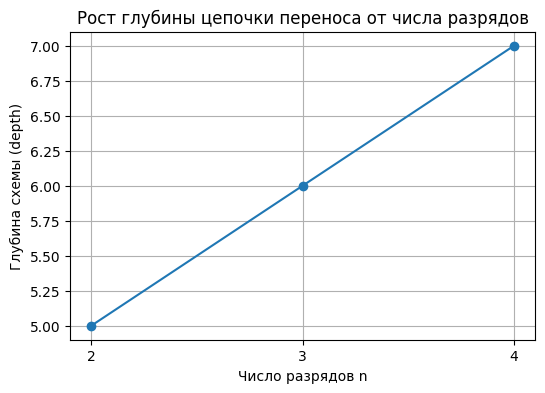

In [16]:

def build_nbit_adder(n_bits, a_val, b_val, measure=False):
  # Кубиты: A[0..n-1], B[0..n-1], S[0..n], Carry[0..n-2] -> всего 4n
  n_q = 4 * n_bits
  qc = QuantumCircuit(n_q, n_bits + 1 if measure else 0)

  for i in range(n_bits):
    if (a_val >> i) & 1:
      qc.x(i)
    if (b_val >> i) & 1:
      qc.x(n_bits + i)

  s_base = 2 * n_bits
  c_base = 3 * n_bits + 1

  for i in range(n_bits):
    a_q = i
    b_q = n_bits + i
    s_q = s_base + i
    x_q = None if i == 0 else (c_base + i - 1)
    out_c_q = (s_base + n_bits) if (i == n_bits - 1) else (c_base + i)

    if x_q is None:
      qc.ccx(a_q, b_q, out_c_q)
      qc.cx(a_q, s_q)
      qc.cx(b_q, s_q)
    else:
      qc.ccx(a_q, b_q, out_c_q)
      qc.cx(a_q, s_q)
      qc.cx(b_q, s_q)
      qc.ccx(x_q, s_q, out_c_q)
      qc.cx(x_q, s_q)

  if measure:
    for k in range(n_bits + 1):
      qc.measure(s_base + k, k)
  return qc

bit_widths = [2, 3, 4]
depths = []

print("Разрядность | Кубитов | CX | CCX | Глубина (depth)")
print("-" * 52)
for n_b in bit_widths:
  qc_s = build_nbit_adder(n_b, 0, 0, measure=False)
  ops = qc_s.count_ops()
  cx_cnt = ops.get("cx", 0)
  ccx_cnt = ops.get("ccx", 0)
  d = qc_s.depth()
  depths.append(d)
  print(f"     {n_b}      |   {qc_s.num_qubits:2d}    | {cx_cnt:2d} |  {ccx_cnt:2d} |       {d}")

# Проверка всех пар
for a in range(16):
  for b in range(16):
    qc_4 = build_nbit_adder(4, a, b, measure=True)
    cnt = sim.run(qc_4, shots=16).result().get_counts()
    assert len(cnt) == 1
    assert int(list(cnt.keys())[0], 2) == a + b
print("Все 256 пар (a, b) для 4-битного сумматора проверены успешно.")

# График
plt.figure(figsize=(6, 4))
plt.plot(bit_widths, depths, marker="o")
plt.xticks(bit_widths)
plt.title("Рост глубины цепочки переноса от числа разрядов")
plt.xlabel("Число разрядов n")
plt.ylabel("Глубина схемы (depth)")
plt.grid(True)
plt.show()

## Задание 2: Вариант 3 — F(A, B, C, D) = (A AND (NOT B)) OR ((NOT C) AND D)

In [17]:
def f_classic(a, b, c, d):
    term1 = a and (not b)
    term2 = (not c) and d
    return int(term1 or term2)

def add_not(qc, q):
    qc.x(q)

def add_and(qc, q1, q2, target):
    qc.ccx(q1, q2, target)

def add_or(qc, q1, q2, target):
    qc.cx(q1, target)
    qc.cx(q2, target)
    qc.ccx(q1, q2, target)

# 4 входа, выход, 3 ancilla
def build_basic_f(a, b, c, d, measure=False):
    qc = QuantumCircuit(8, 4 if measure else 0)
    if a: qc.x(0)
    if b: qc.x(1)
    if c: qc.x(2)
    if d: qc.x(3)

    comp = QuantumCircuit(8)
    add_not(comp, 1)
    add_and(comp, 0, 1, 5)
    add_not(comp, 1)

    add_not(comp, 2)
    add_and(comp, 2, 3, 6)
    add_not(comp, 2)

    add_or(comp, 5, 6, 7)

    qc.compose(comp, inplace=True)
    qc.cx(7, 4)
    qc.compose(comp.inverse(), inplace=True)

    if measure:
        qc.measure(4, 0)
        qc.measure(5, 1)
        qc.measure(6, 2)
        qc.measure(7, 3)
    return qc

# 4 входа, выход, 2 ancilla
def build_opt_f(a, b, c, d, measure=False):
    qc = QuantumCircuit(7, 3 if measure else 0)
    if a: qc.x(0)
    if b: qc.x(1)
    if c: qc.x(2)
    if d: qc.x(3)

    add_not(qc, 4)

    comp = QuantumCircuit(7)
    add_not(comp, 5)
    add_not(comp, 1)
    add_and(comp, 0, 1, 5)
    add_not(comp, 1)

    add_not(comp, 6)
    add_not(comp, 2)
    add_and(comp, 2, 3, 6)
    add_not(comp, 2)

    qc.compose(comp, inplace=True)
    add_and(qc, 5, 6, 4)
    qc.compose(comp.inverse(), inplace=True)

    if measure:
        qc.measure(4, 0)
        qc.measure(5, 1)
        qc.measure(6, 2)
    return qc

print('A B C D | Классика | Квантово (opt) | Ancilla = 0 | Статус')
print('-' * 62)
for a in [0, 1]:
    for b in [0, 1]:
        for c in [0, 1]:
            for d in [0, 1]:
                exp_f = f_classic(a, b, c, d)
                cnt = sim.run(build_opt_f(a, b, c, d, measure=True), shots=100).result().get_counts()
                assert len(cnt) == 1
                out_bits = list(cnt.keys())[0]
                got_f = int(out_bits[-1])
                anc_bits = out_bits[:-1]
                assert got_f == exp_f
                assert anc_bits == '00', f'Ancilla не обнулились: {anc_bits}'
                print(f'{a} {b} {c} {d} |     {exp_f}    |       {got_f}        |     {anc_bits}      | OK')

b_circ = build_basic_f(0, 0, 0, 0, measure=False)
o_circ = build_opt_f(0, 0, 0, 0, measure=False)
print('\nБазовая схема :', 'кубитов=', b_circ.num_qubits,
      'CX=', b_circ.count_ops().get('cx', 0),
      'CCX=', b_circ.count_ops().get('ccx', 0),
      'depth=', b_circ.depth())
print('Оптимизированная:', 'кубитов=', o_circ.num_qubits,
      'CX=', o_circ.count_ops().get('cx', 0),
      'CCX=', o_circ.count_ops().get('ccx', 0),
      'depth=', o_circ.depth())

A B C D | Классика | Квантово (opt) | Ancilla = 0 | Статус
--------------------------------------------------------------
0 0 0 0 |     0    |       0        |     00      | OK
0 0 0 1 |     1    |       1        |     00      | OK
0 0 1 0 |     0    |       0        |     00      | OK
0 0 1 1 |     0    |       0        |     00      | OK
0 1 0 0 |     0    |       0        |     00      | OK
0 1 0 1 |     1    |       1        |     00      | OK
0 1 1 0 |     0    |       0        |     00      | OK
0 1 1 1 |     0    |       0        |     00      | OK
1 0 0 0 |     1    |       1        |     00      | OK
1 0 0 1 |     1    |       1        |     00      | OK
1 0 1 0 |     1    |       1        |     00      | OK
1 0 1 1 |     1    |       1        |     00      | OK
1 1 0 0 |     0    |       0        |     00      | OK
1 1 0 1 |     1    |       1        |     00      | OK
1 1 1 0 |     0    |       0        |     00      | OK
1 1 1 1 |     0    |       0        |     00      | O

## Задание 3: Моделирование шума для оптимизированной схемы Варианта 3

/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


p2 = 0.000 -> доля верных ответов по всем 16 входам: 0.9897
p2 = 0.001 -> доля верных ответов по всем 16 входам: 0.9878
p2 = 0.005 -> доля верных ответов по всем 16 входам: 0.9637
p2 = 0.010 -> доля верных ответов по всем 16 входам: 0.9453
p2 = 0.020 -> доля верных ответов по всем 16 входам: 0.8997


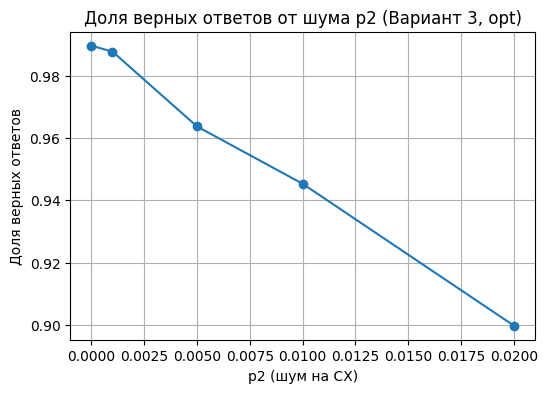

In [18]:
p1 = 0.001
p2_list = [0.0, 0.001, 0.005, 0.01, 0.02]
accuracies = []

for p2 in p2_list:
    noise_model = NoiseModel()
    err_1q = depolarizing_error(p1, 1)
    err_2q = depolarizing_error(p2, 2)
    noise_model.add_all_qubit_quantum_error(err_1q, ['x', 'sx', 'rz'])
    noise_model.add_all_qubit_quantum_error(err_2q, ['cx'])

    correct_total = 0
    shots_per_input = 200
    total_shots = 16 * shots_per_input

    for a in [0, 1]:
        for b in [0, 1]:
            for c in [0, 1]:
                for d in [0, 1]:
                    exp_f = f_classic(a, b, c, d)
                    qc_raw = build_opt_f(a, b, c, d, measure=True)
                    qc_t = transpile(qc_raw, sim, basis_gates=['rz', 'sx', 'x', 'cx'])
                    cnt = sim.run(qc_t, noise_model=noise_model, shots=shots_per_input).result().get_counts()
                    for bitstr, freq in cnt.items():
                        if int(bitstr[-1]) == exp_f:
                            correct_total += freq

    acc = correct_total / total_shots
    accuracies.append(acc)
    print(f'p2 = {p2:5.3f} -> доля верных ответов по всем 16 входам: {acc:.4f}')

plt.figure(figsize=(6, 4))
plt.plot(p2_list, accuracies, marker='o')
plt.title('Доля верных ответов от шума p2 (Вариант 3, opt)')
plt.xlabel('p2 (шум на CX)')
plt.ylabel('Доля верных ответов')
plt.grid(True)
plt.show()

## Задание 4: Оракул, диффузор и алгоритм Гровера

In [19]:
def apply_mcz(qc, qubits):
    target = qubits[-1]
    controls = qubits[:-1]
    qc.h(target)
    qc.mcx(controls, target)
    qc.h(target)

def build_oracle(n, marked):
    qc = QuantumCircuit(n, name='Oracle')
    rev_marked = marked[::-1]
    for i, ch in enumerate(rev_marked):
        if ch == '0':
            qc.x(i)
    apply_mcz(qc, list(range(n)))
    for i, ch in enumerate(rev_marked):
        if ch == '0':
            qc.x(i)
    return qc

def build_diffuser(n):
    qc = QuantumCircuit(n, name='Diffuser')
    for i in range(n):
        qc.h(i)
    for i in range(n):
        qc.x(i)
    apply_mcz(qc, list(range(n)))
    for i in range(n):
        qc.x(i)
    for i in range(n):
        qc.h(i)
    return qc

for n_test in [2, 3, 4, 5]:
    w_str = ('0101101')[-n_test:]
    op_or = Operator(build_oracle(n_test, w_str)).data
    target_idx = int(w_str, 2)
    expected_diag = np.ones(2**n_test)
    expected_diag[target_idx] = -1.0
    assert np.allclose(op_or, np.diag(expected_diag))
print('Оракул проверен для n = 2, 3, 4, 5.')

n_diff = 3
op_diff = Operator(build_diffuser(n_diff)).data
s_vec = np.ones((2**n_diff, 1)) / np.sqrt(2**n_diff)
mat_theory = 2 * (s_vec @ s_vec.T) - np.eye(2**n_diff)
assert np.allclose(op_diff, -mat_theory)
print('Матрица диффузора совпадает с (2|s><s| - I) с точностью до знака (-1).')

def grover_circuit(n, marked_list, iterations):
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.h(i)
    for _ in range(iterations):
        for m_str in marked_list:
            qc.compose(build_oracle(n, m_str), inplace=True)
        qc.compose(build_diffuser(n), inplace=True)
    return qc

n3 = 3
N3 = 2**n3
w3 = '101'
theta3 = np.arcsin(1.0 / np.sqrt(N3))
for k_it in [1, 2]:
    sv = Statevector.from_instruction(grover_circuit(n3, [w3], k_it))
    p_sim = sv.probabilities_dict()[w3]
    p_th = np.sin((2 * k_it + 1) * theta3)**2
    print(f'n=3, k={k_it}: P_схема={p_sim:.6f}, P_формула={p_th:.6f}')

Оракул проверен для n = 2, 3, 4, 5.
Матрица диффузора совпадает с (2|s><s| - I) с точностью до знака (-1).
n=3, k=1: P_схема=0.781250, P_формула=0.781250
n=3, k=2: P_схема=0.945312, P_формула=0.945313


## Задание 5: Состояние |1010011>, k = 0..15 и влияние числа shots

k_opt_exact=8, k_floor=8, k_round=9, k_opt_exp(1024 shots)=8


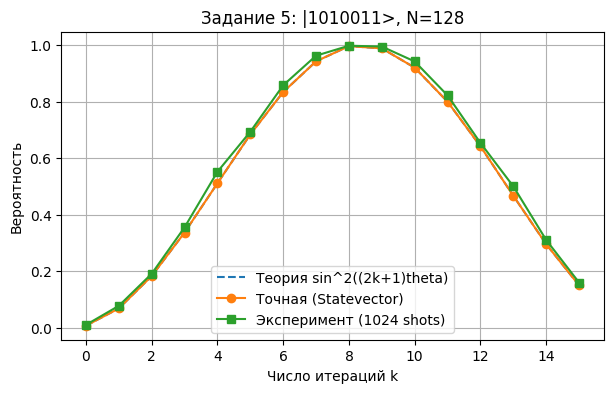

shots=  16 -> совпадений оптимума с теоретическим: 6/20 (30.0%)
shots=  64 -> совпадений оптимума с теоретическим: 18/20 (90.0%)
shots= 256 -> совпадений оптимума с теоретическим: 20/20 (100.0%)
shots=1024 -> совпадений оптимума с теоретическим: 19/20 (95.0%)


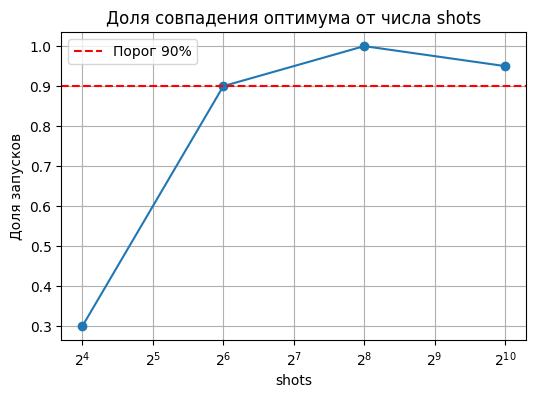

In [20]:
w5 = '1010011'
n5 = len(w5)
N5 = 2**n5
theta5 = np.arcsin(1.0 / np.sqrt(N5))

ks = list(range(16))
p_exact_5 = []
p_exp_5 = []
p_theory_5 = [np.sin((2 * k + 1) * theta5)**2 for k in ks]

for k in ks:
    qc_k = grover_circuit(n5, [w5], k)
    sv_k = Statevector.from_instruction(qc_k)
    p_exact_5.append(sv_k.probabilities_dict().get(w5, 0.0))

    qc_m = qc_k.copy()
    qc_m.measure_all()
    cnt = sim.run(qc_m, shots=1024, seed_simulator=42).result().get_counts()
    p_exp_5.append(cnt.get(w5, 0) / 1024.0)

k_opt_exact = ks[int(np.argmax(p_exact_5))]
k_opt_exp = ks[int(np.argmax(p_exp_5))]
k_floor = int(np.floor((np.pi / 4) * np.sqrt(N5)))
k_round = int(np.round((np.pi / 4) * np.sqrt(N5)))
print(f'k_opt_exact={k_opt_exact}, k_floor={k_floor}, k_round={k_round}, k_opt_exp(1024 shots)={k_opt_exp}')

plt.figure(figsize=(7, 4))
plt.plot(ks, p_theory_5, '--', label='Теория sin^2((2k+1)theta)')
plt.plot(ks, p_exact_5, 'o-', label='Точная (Statevector)')
plt.plot(ks, p_exp_5, 's-', label='Эксперимент (1024 shots)')
plt.title('Задание 5: |1010011>, N=128')
plt.xlabel('Число итераций k')
plt.ylabel('Вероятность')
plt.legend()
plt.grid(True)
plt.show()

shot_levels = [16, 64, 256, 1024]
match_rates = []
for sh in shot_levels:
    matches = 0
    for run_i in range(20):
        exp_curve = []
        for k in ks:
            qc_m = grover_circuit(n5, [w5], k)
            qc_m.measure_all()
            cnt = sim.run(qc_m, shots=sh, seed_simulator=1000 + run_i * 100 + k).result().get_counts()
            exp_curve.append(cnt.get(w5, 0) / sh)
        if ks[int(np.argmax(exp_curve))] == k_opt_exact:
            matches += 1
    rate = matches / 20.0
    match_rates.append(rate)
    print(f'shots={sh:4d} -> совпадений оптимума с теоретическим: {matches}/20 ({rate*100:.1f}%)')

plt.figure(figsize=(6, 4))
plt.plot(shot_levels, match_rates, marker='o')
plt.axhline(0.9, color='r', linestyle='--', label='Порог 90%')
plt.xscale('log', base=2)
plt.title('Доля совпадения оптимума от числа shots')
plt.xlabel('shots')
plt.ylabel('Доля запусков')
plt.legend()
plt.grid(True)
plt.show()

## Задание 6: Несколько решений M при N = 2^6 = 64

In [21]:
rng = np.random.default_rng(123)
n6 = 6
N6 = 2**n6
all_states_6 = [format(i, f'0{n6}b') for i in range(N6)]

print('M  | k_теор | k_первый_макс | P_в_максимуме')
print('-' * 45)
for m_val in [1, 2, 3, 4, 8]:
    chosen = list(rng.choice(all_states_6, size=m_val, replace=False))
    k_th_m = int(np.floor((np.pi / 4) * np.sqrt(N6 / m_val)))

    probs_m = []
    for k in ks:
        sv_m = Statevector.from_instruction(grover_circuit(n6, chosen, k))
        p_dict = sv_m.probabilities_dict()
        probs_m.append(sum(p_dict.get(st, 0.0) for st in chosen))

    first_peak_k = 0
    for idx in range(1, len(probs_m)):
        if probs_m[idx] >= probs_m[idx - 1]:
            first_peak_k = idx
        else:
            break

    global_peak_k = ks[int(np.argmax(probs_m))]
    print(f'{m_val:2d} |   {k_th_m:2d}   |      {first_peak_k:2d}       |     '
          f'{probs_m[first_peak_k]:.4f} (глоб. max на k={global_peak_k}: {max(probs_m):.4f})')

for frac_label, m_edge in [('M = N/2 (32)', N6 // 2), ('M = 3N/4 (48)', (3 * N6) // 4)]:
    chosen_edge = list(rng.choice(all_states_6, size=m_edge, replace=False))
    edge_probs = []
    for k in [0, 1, 2, 3]:
        sv_e = Statevector.from_instruction(grover_circuit(n6, chosen_edge, k))
        p_d = sv_e.probabilities_dict()
        edge_probs.append(sum(p_d.get(st, 0.0) for st in chosen_edge))
    print(f'{frac_label}: вероятности для k=0..3 -> {[round(x, 4) for x in edge_probs]}')

M  | k_теор | k_первый_макс | P_в_максимуме
---------------------------------------------
 1 |    6   |       6       |     0.9966 (глоб. max на k=6: 0.9966)
 2 |    4   |       4       |     0.9992 (глоб. max на k=4: 0.9992)
 3 |    3   |       3       |     0.9981 (глоб. max на k=3: 0.9981)
 4 |    3   |       3       |     0.9613 (глоб. max на k=15: 0.9996)
 8 |    2   |       2       |     0.9453 (глоб. max на k=6: 0.9998)
M = N/2 (32): вероятности для k=0..3 -> [np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5)]
M = 3N/4 (48): вероятности для k=0..3 -> [np.float64(0.75), np.float64(0.0), np.float64(0.75), np.float64(0.75)]


## Задание 7: Вариант 3 (N = 2^5 = 32, |w> = |11001>) и шум

Вариант 3 (N=32, |11001>): k_теор=4, k_точн=4, k_эксп=4, max P_точн=0.9992


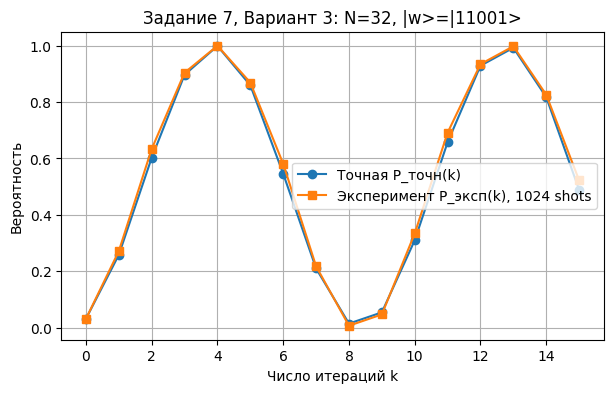

/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/pyth

Шум p2=0.005: max P=0.3701 на k=3 (глубина при k=3: 455)


/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(
/usr/local/lib/pyth

Шум p2=0.02: max P=0.0859 на k=2 (глубина при k=2: 304)


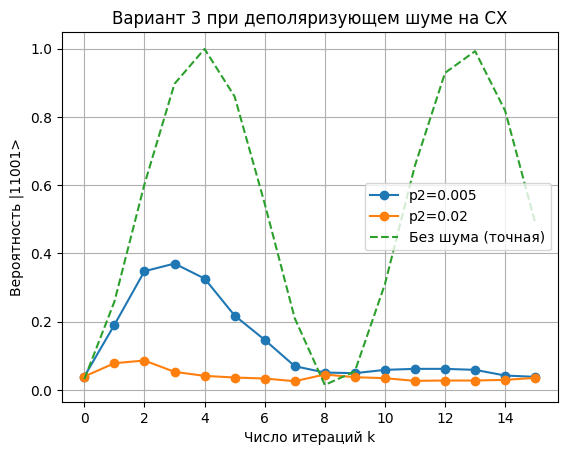

In [22]:
w_var3 = '11001'
n_var3 = 5
N_var3 = 2**n_var3

p_ex_3 = []
p_ex_3_shots = []
for k in ks:
    qc_3 = grover_circuit(n_var3, [w_var3], k)
    p_ex_3.append(Statevector.from_instruction(qc_3).probabilities_dict().get(w_var3, 0.0))

    qc_3m = qc_3.copy()
    qc_3m.measure_all()
    cnt3 = sim.run(qc_3m, shots=1024, seed_simulator=33).result().get_counts()
    p_ex_3_shots.append(cnt3.get(w_var3, 0) / 1024.0)

k_th_3 = int(np.floor((np.pi / 4) * np.sqrt(N_var3)))
k_ex_3 = ks[int(np.argmax(p_ex_3))]
k_sp_3 = ks[int(np.argmax(p_ex_3_shots))]
print(f'Вариант 3 (N=32, |11001>): k_теор={k_th_3}, k_точн={k_ex_3}, k_эксп={k_sp_3}, max P_точн={max(p_ex_3):.4f}')

plt.figure(figsize=(7, 4))
plt.plot(ks, p_ex_3, 'o-', label='Точная P_точн(k)')
plt.plot(ks, p_ex_3_shots, 's-', label='Эксперимент P_эксп(k), 1024 shots')
plt.title('Задание 7, Вариант 3: N=32, |w>=|11001>')
plt.xlabel('Число итераций k')
plt.ylabel('Вероятность')
plt.legend()
plt.grid(True)
plt.show()

for p2_n in [0.005, 0.02]:
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p2_n, 2), ['cx'])
    noisy_curve = []
    for k in ks:
        qc_raw = grover_circuit(n_var3, [w_var3], k)
        qc_raw.measure_all()
        qc_tr = transpile(qc_raw, sim, basis_gates=['rz', 'sx', 'x', 'cx'])
        c_noisy = sim.run(qc_tr, noise_model=nm, shots=1024, seed_simulator=77 + k).result().get_counts()
        noisy_curve.append(c_noisy.get(w_var3, 0) / 1024.0)
    best_k_noisy = ks[int(np.argmax(noisy_curve))]
    tr_best = transpile(grover_circuit(n_var3, [w_var3], best_k_noisy), sim, basis_gates=['rz', 'sx', 'x', 'cx'])
    print(f'Шум p2={p2_n}: max P={max(noisy_curve):.4f} на k={best_k_noisy} '
          f'(глубина при k={best_k_noisy}: {tr_best.depth()})')
    plt.plot(ks, noisy_curve, 'o-', label=f'p2={p2_n}')

plt.plot(ks, p_ex_3, '--', label='Без шума (точная)')
plt.title('Вариант 3 при деполяризующем шуме на CX')
plt.xlabel('Число итераций k')
plt.ylabel('Вероятность |11001>')
plt.legend()
plt.grid(True)
plt.show()